<a href="https://colab.research.google.com/github/durgajc/portfolio_durga/blob/ai-ml/grayscale.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

In [ ]:
# Load the MNIST dataset (images and labels)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [ ]:
# Preprocess the data - Reshape the data to fit the CNN input grayscale images
x_train = x_train.reshape((x_train.shape[0], 28, 28, 1))
x_test = x_test.reshape((x_test.shape[0], 28, 28, 1))
# Normalize pixel values to be between 0 and 1
x_train, x_test = x_train / 255.0, x_test / 255.0

In [ ]:
# Build the CNN model
model = models.Sequential()
# First Convolutional Layer
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(layers.MaxPooling2D((2, 2)))
# Second Convolutional Layer
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
# Third Convolutional Layer
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
# Flatten the results from the convolutional layers
model.add(layers.Flatten())
# Fully Connected Layer
model.add(layers.Dense(64, activation='relu'))
# Output layer with 10 neurons for classification (digits 0-9)
model.add(layers.Dense(10, activation='softmax'))

In [ ]:
# Compile the model with appropriate loss function, optimizer, and metrics
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
# Train the model
model.fit(x_train, y_train, epochs=4, batch_size=64, validation_data=(x_test, y_test))

Epoch 1/4
938/938 ━━━━━━━━━━━━━━━━━━━━ 54s 57ms/step - accuracy: 0.9431 - loss: 0.1848 - val_accuracy: 0.9804 - val_loss: 0.0604
Epoch 2/4
938/938 ━━━━━━━━━━━━━━━━━━━━ 52s 56ms/step - accuracy: 0.9846 - loss: 0.0512 - val_accuracy: 0.9880 - val_loss: 0.0358
Epoch 3/4
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 56ms/step - accuracy: 0.9884 - loss: 0.0375 - val_accuracy: 0.9890 - val_loss: 0.0350
Epoch 4/4
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 55ms/step - accuracy: 0.9912 - loss: 0.0284 - val_accuracy: 0.9869 - val_loss: 0.0387


In [ ]:
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"Test accuracy: {test_acc * 100:.2f}%")

313/313 - 3s - 8ms/step - accuracy: 0.9869 - loss: 0.0387
Test accuracy: 98.69%


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


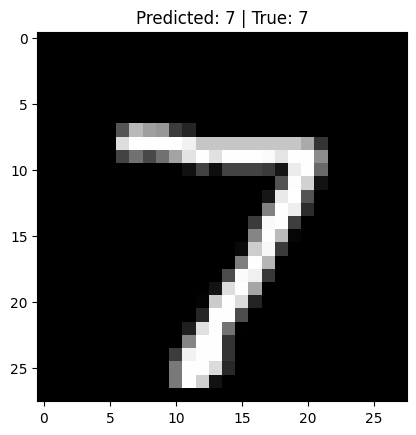

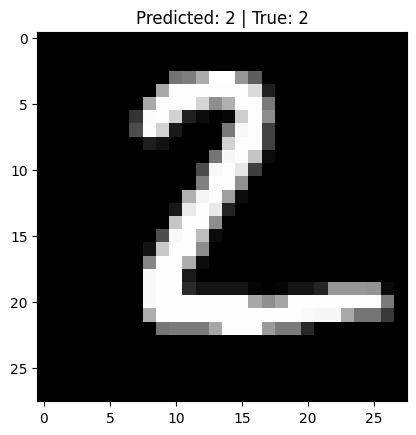

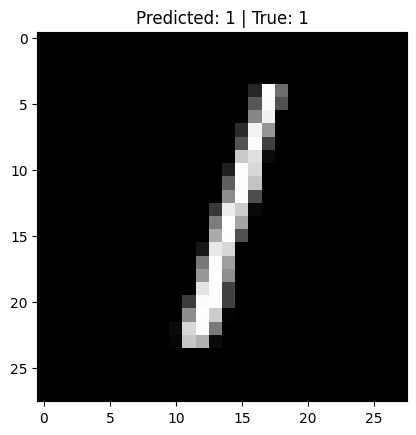

In [ ]:
# visualize some predictions
predictions = model.predict(x_test)
# Visualizing the first few test images and their predictions
for i in range(3):
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {predictions[i].argmax()} | True: {y_test[i]}")
    plt.show()